# 05 Component Influence Analysis

This notebook uses only `data/processed/dfsi_verified_baseline.csv` and restricts analysis to the 709 complete valid records. It isolates methodological sensitivity relative to the corrected reconstructed DFSI baseline and does not compare alternative designs against published DFSI.

## Setup

In [1]:
from pathlib import Path
import math

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", 180)
pd.set_option("display.max_colwidth", 180)

EXPECTED_BASELINE = Path("data") / "processed" / "dfsi_verified_baseline.csv"


def find_project_root(start_path):
    start_path = Path(start_path).resolve()
    for candidate in [start_path, *start_path.parents]:
        if (candidate / EXPECTED_BASELINE).exists():
            return candidate
    raise FileNotFoundError("Could not find data/processed/dfsi_verified_baseline.csv from the current working directory.")


PROJECT_ROOT = find_project_root(Path.cwd())
BASELINE_PATH = PROJECT_ROOT / EXPECTED_BASELINE
TABLE_DIR = PROJECT_ROOT / "outputs" / "tables"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"
TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print(f"Project root: {PROJECT_ROOT}")
print(f"Input baseline: {BASELINE_PATH.relative_to(PROJECT_ROOT)}")

Project root: /Users/abhijithshaji/Documents/india-flood-index-robustness
Input baseline: data/processed/dfsi_verified_baseline.csv


## Load Complete Valid Baseline Records

In [2]:
baseline_source = pd.read_csv(BASELINE_PATH)
print(f"Verified baseline rows: {len(baseline_source):,}")
print(list(baseline_source.columns))

required_columns = [
    "State_Name",
    "district_name",
    "available_state_identifier",
    "available_state_review_key",
    "available_district_identifier",
    "available_district_review_key",
    "available_district_lgd_codes",
    "available_district_lgd_code_count",
    "flood_event_count",
    "mean_flood_duration",
    "fatalities",
    "injured",
    "corrected_percent_flooded_area",
    "population",
    "reconstructed_dfsi",
    "reconstructed_rank",
    "completeness_status",
    "join_status",
]
missing_columns = [column for column in required_columns if column not in baseline_source.columns]
if missing_columns:
    raise KeyError(f"Missing required baseline columns: {missing_columns}")

analysis = baseline_source.query("completeness_status == 'complete' and join_status == 'one_to_one_comparison_record'").copy()
component_input_columns = [
    "flood_event_count",
    "mean_flood_duration",
    "fatalities",
    "injured",
    "corrected_percent_flooded_area",
    "population",
]
for column in component_input_columns:
    analysis[column] = pd.to_numeric(analysis[column], errors="coerce").astype("float64")
analysis = analysis.dropna(subset=component_input_columns + ["reconstructed_dfsi"]).copy()

assert len(analysis) == 709, f"Expected 709 complete valid records, got {len(analysis)}"
for column in component_input_columns:
    assert analysis[column].ge(0).all(), f"Negative component values found in {column}"
assert analysis["population"].gt(0).all(), "Population must be positive."

print(f"Complete valid records used: {len(analysis):,}")
display(analysis.head())

Verified baseline rows: 720
['State_Name', 'district_name', 'available_state_identifier', 'available_state_review_key', 'available_district_identifier', 'available_district_review_key', 'available_district_lgd_codes', 'available_district_lgd_code_count', 'inventory_district_names', 'dfsi_source_row_id', 'impact_source_row_id', 'area_source_row_id', 'flood_event_count', 'mean_flood_duration', 'fatalities', 'injured', 'corrected_percent_flooded_area', 'population', 'published_dfsi', 'reconstructed_dfsi', 'reconstructed_dfsi_product_space', 'log_product_agreement_abs_diff', 'published_rank', 'reconstructed_rank', 'numerical_difference', 'absolute_difference', 'rank_difference', 'absolute_rank_difference', 'completeness_status', 'join_status']
Complete valid records used: 709


,State_Name,district_name,available_state_identifier,available_state_review_key,available_district_identifier,available_district_review_key,available_district_lgd_codes,available_district_lgd_code_count,inventory_district_names,dfsi_source_row_id,impact_source_row_id,area_source_row_id,flood_event_count,mean_flood_duration,fatalities,injured,corrected_percent_flooded_area,population,published_dfsi,reconstructed_dfsi,reconstructed_dfsi_product_space,log_product_agreement_abs_diff,published_rank,reconstructed_rank,numerical_difference,absolute_difference,rank_difference,absolute_rank_difference,completeness_status,join_status
0,DADRA & NAGAR HAVE,Dadra & Nagar Haveli,DADRA & NAGAR HAVE,dadra & nagar have,Dadra & Nagar Haveli,dadra & nagar haveli,NaN,0,NaN,653,0,0,0.0,1.0,10.0,0.0,2.969168,618459.0,9.820211,8.773826,8.773826,0.0,630.0,637.0,-1.046385,1.046385,7.0,7.0,complete,one_to_one_comparison_record
3,ANDAMAN & NICOBAR,North & Middle Andaman,ANDAMAN & NICOBAR,andaman & nicobar,North & Middle Andaman,north & middle andaman,NaN,0,NaN,726,3,3,0.0,1.0,0.0,0.0,1.314817,101677.0,7.462575,5.672769,5.672769,0.0,703.0,709.0,-1.789805,1.789805,6.0,6.0,complete,one_to_one_comparison_record
4,ANDAMAN & NICOBAR,South Andaman,ANDAMAN & NICOBAR,andaman & nicobar,South Andaman,south andaman,NaN,0,NaN,703,4,4,0.0,2.0,1.0,0.0,1.443452,257900.0,8.360463,6.878636,6.878636,0.0,680.0,697.0,-1.481827,1.481827,17.0,17.0,complete,one_to_one_comparison_record
6,ANDHRA PRADESH,Srikakulam,ANDHRA PRADESH,andhra pradesh,Srikakulam,srikakulam,519.0,1,Srikakulam,237,6,6,22.0,6.0,144.0,0.0,3.446704,2726592.0,15.261049,13.613220,13.613220,0.0,218.0,265.0,-1.647829,1.647829,47.0,47.0,complete,one_to_one_comparison_record
7,ANDHRA PRADESH,Vizianagaram,ANDHRA PRADESH,andhra pradesh,Vizianagaram,vizianagaram,521.0,1,Vizianagaram,173,7,7,17.0,9.0,63.0,107.0,0.790002,2443656.0,15.961002,14.541950,14.541950,0.0,161.0,168.0,-1.419052,1.419052,7.0,7.0,complete,one_to_one_comparison_record


## Reconstruct Baseline Term Contributions

The six term contributions are rebuilt from the verified processed baseline columns. The reconstructed baseline is asserted to match `reconstructed_dfsi` within numerical tolerance.

In [3]:
term_definitions = [
    {
        "component": "flood_events",
        "term_column": "term_events",
        "input_column": "flood_event_count",
        "non_population": True,
    },
    {
        "component": "mean_duration",
        "term_column": "term_duration",
        "input_column": "mean_flood_duration",
        "non_population": True,
    },
    {
        "component": "fatalities",
        "term_column": "term_fatalities",
        "input_column": "fatalities",
        "non_population": True,
    },
    {
        "component": "injured_people",
        "term_column": "term_injured",
        "input_column": "injured",
        "non_population": True,
    },
    {
        "component": "flooded_area",
        "term_column": "term_flooded_area",
        "input_column": "corrected_percent_flooded_area",
        "non_population": True,
    },
    {
        "component": "population",
        "term_column": "term_population",
        "input_column": "population",
        "non_population": False,
    },
]
term_df = pd.DataFrame(term_definitions)
term_columns = term_df["term_column"].tolist()
non_population_term_columns = term_df.loc[term_df["non_population"], "term_column"].tolist()

analysis["term_events"] = np.log10(1.0 + analysis["flood_event_count"])
analysis["term_duration"] = np.log10(1.0 + analysis["mean_flood_duration"])
analysis["term_fatalities"] = 2.0 * np.log10(1.0 + analysis["fatalities"])
analysis["term_injured"] = np.log10(1.0 + analysis["injured"])
analysis["term_flooded_area"] = np.log10(1.0 + analysis["corrected_percent_flooded_area"])
analysis["term_population"] = np.log10(analysis["population"])
analysis["baseline_dfsi"] = analysis[term_columns].sum(axis=1)
analysis["baseline_rank"] = analysis["baseline_dfsi"].rank(ascending=False, method="min").astype("int64")

max_reconstruction_diff = (analysis["baseline_dfsi"] - analysis["reconstructed_dfsi"]).abs().max()
assert max_reconstruction_diff <= 1e-10, f"Reconstructed baseline mismatch: {max_reconstruction_diff}"
assert analysis[term_columns].ge(0).all().all(), "All term contributions must be nonnegative."
assert analysis.loc[analysis["baseline_rank"].eq(1), "baseline_dfsi"].eq(analysis["baseline_dfsi"].max()).all(), "Baseline rank 1 is not maximum DFSI."

nonpop_max = analysis[non_population_term_columns].max(axis=1)
for row in term_df.itertuples(index=False):
    if row.non_population:
        analysis[f"{row.term_column}_is_largest_non_population_term"] = analysis[row.term_column].eq(nonpop_max)

print(f"Max difference between reconstructed baseline and verified reconstructed DFSI: {max_reconstruction_diff}")
display(analysis[["State_Name", "district_name", *component_input_columns, *term_columns, "baseline_dfsi", "baseline_rank"]].head())

Max difference between reconstructed baseline and verified reconstructed DFSI: 1.7763568394002505e-15


,State_Name,district_name,flood_event_count,mean_flood_duration,fatalities,injured,corrected_percent_flooded_area,population,term_events,term_duration,term_fatalities,term_injured,term_flooded_area,term_population,baseline_dfsi,baseline_rank
0,DADRA & NAGAR HAVE,Dadra & Nagar Haveli,0.0,1.0,10.0,0.0,2.969168,618459.0,0.000000,0.301030,2.082785,0.000000,0.598699,5.791311,8.773826,637
3,ANDAMAN & NICOBAR,North & Middle Andaman,0.0,1.0,0.0,0.0,1.314817,101677.0,0.000000,0.301030,0.000000,0.000000,0.364517,5.007223,5.672769,709
4,ANDAMAN & NICOBAR,South Andaman,0.0,2.0,1.0,0.0,1.443452,257900.0,0.000000,0.477121,0.602060,0.000000,0.388004,5.411451,6.878636,697
6,ANDHRA PRADESH,Srikakulam,22.0,6.0,144.0,0.0,3.446704,2726592.0,1.361728,0.845098,4.322736,0.000000,0.648038,6.435620,13.613220,265
7,ANDHRA PRADESH,Vizianagaram,17.0,9.0,63.0,107.0,0.790002,2443656.0,1.255273,1.000000,3.612360,2.033424,0.252854,6.388040,14.541950,168


## Part A — Component Contribution Audit

These are descriptive associations and contribution summaries. Correlations are not interpreted as causal importance.

In [4]:
summary_records = []
for row in term_df.itertuples(index=False):
    values = analysis[row.term_column]
    contribution_percent = values / analysis["baseline_dfsi"] * 100.0
    if row.non_population:
        largest_count = int(analysis[f"{row.term_column}_is_largest_non_population_term"].sum())
        largest_percent = largest_count / len(analysis) * 100.0
    else:
        largest_count = np.nan
        largest_percent = np.nan

    summary_records.append({
        "component": row.component,
        "term_column": row.term_column,
        "input_column": row.input_column,
        "minimum": values.min(),
        "maximum": values.max(),
        "mean": values.mean(),
        "median": values.median(),
        "standard_deviation": values.std(ddof=1),
        "interquartile_range": values.quantile(0.75) - values.quantile(0.25),
        "median_percentage_contribution_to_total_dfsi": contribution_percent.median(),
        "spearman_correlation_with_baseline_dfsi": values.corr(analysis["baseline_dfsi"], method="spearman"),
        "spearman_correlation_with_baseline_rank": values.corr(analysis["baseline_rank"], method="spearman"),
        "zero_term_district_count": int(values.eq(0).sum()),
        "largest_non_population_term_count": largest_count,
        "largest_non_population_term_percent": largest_percent,
        "interpretation_note": "Correlation is descriptive association, not causal importance.",
    })

component_summary = pd.DataFrame(summary_records)
component_summary.to_csv(TABLE_DIR / "dfsi_component_contribution_summary.csv", index=False)
display(component_summary)

by_district_columns = [
    "State_Name",
    "district_name",
    "available_state_identifier",
    "available_state_review_key",
    "available_district_identifier",
    "available_district_review_key",
    "available_district_lgd_codes",
    "available_district_lgd_code_count",
    *component_input_columns,
    *term_columns,
    "baseline_dfsi",
    "baseline_rank",
]
component_contributions_by_district = analysis[by_district_columns].copy()
for row in term_df.itertuples(index=False):
    component_contributions_by_district[f"{row.component}_percentage_contribution"] = analysis[row.term_column] / analysis["baseline_dfsi"] * 100.0
component_contributions_by_district["largest_non_population_term"] = analysis[non_population_term_columns].idxmax(axis=1).map(
    dict(zip(term_df["term_column"], term_df["component"]))
)
component_contributions_by_district.to_csv(TABLE_DIR / "dfsi_component_contributions_by_district.csv", index=False)
display(component_contributions_by_district.head())

,component,term_column,input_column,minimum,maximum,mean,median,standard_deviation,interquartile_range,median_percentage_contribution_to_total_dfsi,spearman_correlation_with_baseline_dfsi,spearman_correlation_with_baseline_rank,zero_term_district_count,largest_non_population_term_count,largest_non_population_term_percent,interpretation_note
0,flood_events,term_events,flood_event_count,0.000000,2.365488,1.223007,1.380211,0.578178,0.625541,10.721350,0.810806,-0.810806,78,30.0,4.231312,"Correlation is descriptive association, not causal importance."
1,mean_duration,term_duration,mean_flood_duration,0.301030,1.556303,0.968566,0.903090,0.300783,0.477121,7.714917,0.385043,-0.385043,0,38.0,5.359661,"Correlation is descriptive association, not causal importance."
2,fatalities,term_fatalities,fatalities,0.000000,6.474585,3.136154,3.415140,1.345131,1.944833,26.144410,0.922986,-0.922986,25,646.0,91.114245,"Correlation is descriptive association, not causal importance."
3,injured_people,term_injured,injured,0.000000,2.827369,0.646380,0.602060,0.611628,1.041393,4.496081,0.648199,-0.648199,213,3.0,0.423131,"Correlation is descriptive association, not causal importance."
4,flooded_area,term_flooded_area,corrected_percent_flooded_area,0.000032,1.391322,0.425128,0.350066,0.333754,0.474784,3.018811,0.326399,-0.326399,0,3.0,0.423131,"Correlation is descriptive association, not causal importance."
5,population,term_population,population,3.851870,7.127234,6.084399,6.187981,0.514043,0.531237,47.839248,0.643294,-0.643294,0,NaN,NaN,"Correlation is descriptive association, not causal importance."


,State_Name,district_name,available_state_identifier,available_state_review_key,available_district_identifier,available_district_review_key,available_district_lgd_codes,available_district_lgd_code_count,flood_event_count,mean_flood_duration,fatalities,injured,corrected_percent_flooded_area,population,term_events,term_duration,term_fatalities,term_injured,term_flooded_area,term_population,baseline_dfsi,baseline_rank,flood_events_percentage_contribution,mean_duration_percentage_contribution,fatalities_percentage_contribution,injured_people_percentage_contribution,flooded_area_percentage_contribution,population_percentage_contribution,largest_non_population_term
0,DADRA & NAGAR HAVE,Dadra & Nagar Haveli,DADRA & NAGAR HAVE,dadra & nagar have,Dadra & Nagar Haveli,dadra & nagar haveli,NaN,0,0.0,1.0,10.0,0.0,2.969168,618459.0,0.000000,0.301030,2.082785,0.000000,0.598699,5.791311,8.773826,637,0.000000,3.431000,23.738623,0.000000,6.823699,66.006678,fatalities
3,ANDAMAN & NICOBAR,North & Middle Andaman,ANDAMAN & NICOBAR,andaman & nicobar,North & Middle Andaman,north & middle andaman,NaN,0,0.0,1.0,0.0,0.0,1.314817,101677.0,0.000000,0.301030,0.000000,0.000000,0.364517,5.007223,5.672769,709,0.000000,5.306579,0.000000,0.000000,6.425727,88.267694,flooded_area
4,ANDAMAN & NICOBAR,South Andaman,ANDAMAN & NICOBAR,andaman & nicobar,South Andaman,south andaman,NaN,0,0.0,2.0,1.0,0.0,1.443452,257900.0,0.000000,0.477121,0.602060,0.000000,0.388004,5.411451,6.878636,697,0.000000,6.936277,8.752607,0.000000,5.640709,78.670407,fatalities
6,ANDHRA PRADESH,Srikakulam,ANDHRA PRADESH,andhra pradesh,Srikakulam,srikakulam,519.0,1,22.0,6.0,144.0,0.0,3.446704,2726592.0,1.361728,0.845098,4.322736,0.000000,0.648038,6.435620,13.613220,265,10.002981,6.207922,31.753956,0.000000,4.760360,47.274782,fatalities
7,ANDHRA PRADESH,Vizianagaram,ANDHRA PRADESH,andhra pradesh,Vizianagaram,vizianagaram,521.0,1,17.0,9.0,63.0,107.0,0.790002,2443656.0,1.255273,1.000000,3.612360,2.033424,0.252854,6.388040,14.541950,168,8.632078,6.876657,24.840960,13.983158,1.738787,43.928360,fatalities


## Part B — Leave-One-Component-Out Analysis

Each alternative removes one term from the reconstructed baseline, then recalculates ranks in descending order.

In [5]:
loo_specs = [
    {"removed_component": "flood_events", "removed_term": "term_events", "variant_label": "without flood events"},
    {"removed_component": "mean_duration", "removed_term": "term_duration", "variant_label": "without mean duration"},
    {"removed_component": "fatalities", "removed_term": "term_fatalities", "variant_label": "without fatalities"},
    {"removed_component": "injured_people", "removed_term": "term_injured", "variant_label": "without injured people"},
    {"removed_component": "flooded_area", "removed_term": "term_flooded_area", "variant_label": "without flooded area"},
    {"removed_component": "population", "removed_term": "term_population", "variant_label": "without population"},
]

baseline_top10_n = math.ceil(len(analysis) * 0.10)
baseline_top10 = set(analysis.loc[analysis["baseline_rank"].le(baseline_top10_n), "available_district_review_key"])
baseline_top25 = set(analysis.loc[analysis["baseline_rank"].le(25), "available_district_review_key"])
baseline_top50 = set(analysis.loc[analysis["baseline_rank"].le(50), "available_district_review_key"])
baseline_top100 = set(analysis.loc[analysis["baseline_rank"].le(100), "available_district_review_key"])

ranking_frames = []
summary_records = []
top10_change_records = []
largest_change_records = []

for spec in loo_specs:
    variant = analysis.copy()
    variant["removed_component"] = spec["removed_component"]
    variant["removed_term"] = spec["removed_term"]
    variant["variant_label"] = spec["variant_label"]
    variant["leave_one_out_score"] = variant["baseline_dfsi"] - variant[spec["removed_term"]]
    assert np.isfinite(variant["leave_one_out_score"]).all(), f"Non-finite score for {spec['variant_label']}"
    variant["leave_one_out_rank"] = variant["leave_one_out_score"].rank(ascending=False, method="min").astype("int64")
    assert variant.loc[variant["leave_one_out_rank"].eq(1), "leave_one_out_score"].eq(variant["leave_one_out_score"].max()).all(), f"Rank 1 is not max score for {spec['variant_label']}"

    variant["rank_change"] = variant["leave_one_out_rank"] - variant["baseline_rank"]
    variant["absolute_rank_change"] = variant["rank_change"].abs()
    variant["score_difference"] = variant["leave_one_out_score"] - variant["baseline_dfsi"]
    variant["absolute_score_difference"] = variant["score_difference"].abs()
    variant["moved_more_than_10_positions"] = variant["absolute_rank_change"].gt(10)
    variant["moved_more_than_25_positions"] = variant["absolute_rank_change"].gt(25)
    variant["moved_more_than_50_positions"] = variant["absolute_rank_change"].gt(50)
    variant["moved_more_than_100_positions"] = variant["absolute_rank_change"].gt(100)
    variant["in_baseline_top10_percent"] = variant["baseline_rank"].le(baseline_top10_n)
    variant["in_leave_one_out_top10_percent"] = variant["leave_one_out_rank"].le(baseline_top10_n)
    variant["in_leave_one_out_top25"] = variant["leave_one_out_rank"].le(25)
    variant["in_leave_one_out_top50"] = variant["leave_one_out_rank"].le(50)
    variant["in_leave_one_out_top100"] = variant["leave_one_out_rank"].le(100)

    variant_top10 = set(variant.loc[variant["in_leave_one_out_top10_percent"], "available_district_review_key"])
    variant_top25 = set(variant.loc[variant["in_leave_one_out_top25"], "available_district_review_key"])
    variant_top50 = set(variant.loc[variant["in_leave_one_out_top50"], "available_district_review_key"])
    variant_top100 = set(variant.loc[variant["in_leave_one_out_top100"], "available_district_review_key"])

    entered_top10 = sorted(variant_top10 - baseline_top10)
    left_top10 = sorted(baseline_top10 - variant_top10)

    summary_records.append({
        "removed_component": spec["removed_component"],
        "variant_label": spec["variant_label"],
        "record_count": len(variant),
        "spearman_correlation_with_complete_baseline_index": variant["leave_one_out_score"].corr(variant["baseline_dfsi"], method="spearman"),
        "median_absolute_rank_change": variant["absolute_rank_change"].median(),
        "mean_absolute_rank_change": variant["absolute_rank_change"].mean(),
        "maximum_absolute_rank_change": variant["absolute_rank_change"].max(),
        "top_10_percent_n": baseline_top10_n,
        "top_10_percent_overlap_count": len(variant_top10 & baseline_top10),
        "top_10_percent_overlap_share": len(variant_top10 & baseline_top10) / len(baseline_top10),
        "top_25_overlap_count": len(variant_top25 & baseline_top25),
        "top_25_overlap_share": len(variant_top25 & baseline_top25) / len(baseline_top25),
        "top_50_overlap_count": len(variant_top50 & baseline_top50),
        "top_50_overlap_share": len(variant_top50 & baseline_top50) / len(baseline_top50),
        "top_100_overlap_count": len(variant_top100 & baseline_top100),
        "top_100_overlap_share": len(variant_top100 & baseline_top100) / len(baseline_top100),
        "districts_entering_top_10_percent_count": len(entered_top10),
        "districts_leaving_top_10_percent_count": len(left_top10),
        "districts_moving_more_than_10_positions": int(variant["moved_more_than_10_positions"].sum()),
        "districts_moving_more_than_25_positions": int(variant["moved_more_than_25_positions"].sum()),
        "districts_moving_more_than_50_positions": int(variant["moved_more_than_50_positions"].sum()),
        "districts_moving_more_than_100_positions": int(variant["moved_more_than_100_positions"].sum()),
    })

    for change_type, keys in [("entered_top_10_percent", entered_top10), ("left_top_10_percent", left_top10)]:
        changed = variant.loc[variant["available_district_review_key"].isin(keys)].copy()
        if changed.empty:
            top10_change_records.append({
                "removed_component": spec["removed_component"],
                "variant_label": spec["variant_label"],
                "change_type": change_type,
                "State_Name": pd.NA,
                "district_name": pd.NA,
                "available_district_review_key": pd.NA,
                "baseline_rank": pd.NA,
                "leave_one_out_rank": pd.NA,
                "rank_change": pd.NA,
            })
        else:
            changed = changed.sort_values("leave_one_out_rank" if change_type == "entered_top_10_percent" else "baseline_rank")
            for row in changed.itertuples(index=False):
                top10_change_records.append({
                    "removed_component": spec["removed_component"],
                    "variant_label": spec["variant_label"],
                    "change_type": change_type,
                    "State_Name": row.State_Name,
                    "district_name": row.district_name,
                    "available_district_review_key": row.available_district_review_key,
                    "baseline_rank": row.baseline_rank,
                    "leave_one_out_rank": row.leave_one_out_rank,
                    "rank_change": row.rank_change,
                })

    upward = variant.sort_values("rank_change", ascending=True).head(20).copy()
    upward["movement_direction"] = "upward"
    downward = variant.sort_values("rank_change", ascending=False).head(20).copy()
    downward["movement_direction"] = "downward"
    largest_change_records.append(pd.concat([upward, downward], ignore_index=True))

    ranking_frames.append(variant)

loo_rankings = pd.concat(ranking_frames, ignore_index=True)
loo_summary = pd.DataFrame(summary_records)
loo_top10_changes = pd.DataFrame(top10_change_records)
loo_largest_changes = pd.concat(largest_change_records, ignore_index=True)

assert len(loo_rankings) == 709 * len(loo_specs), "Leave-one-out rankings do not contain exactly 709 records per analysis."
assert loo_rankings.groupby("removed_component").size().eq(709).all(), "Each leave-one-out analysis must contain exactly 709 records."

ranking_output_columns = [
    "removed_component",
    "variant_label",
    "State_Name",
    "district_name",
    "available_state_identifier",
    "available_state_review_key",
    "available_district_identifier",
    "available_district_review_key",
    "baseline_dfsi",
    "leave_one_out_score",
    "baseline_rank",
    "leave_one_out_rank",
    "rank_change",
    "absolute_rank_change",
    "score_difference",
    "absolute_score_difference",
    "moved_more_than_10_positions",
    "moved_more_than_25_positions",
    "moved_more_than_50_positions",
    "moved_more_than_100_positions",
    "in_baseline_top10_percent",
    "in_leave_one_out_top10_percent",
]
loo_rankings[ranking_output_columns].to_csv(TABLE_DIR / "dfsi_leave_one_out_rankings.csv", index=False)
loo_summary.to_csv(TABLE_DIR / "dfsi_leave_one_out_summary.csv", index=False)
loo_top10_changes.to_csv(TABLE_DIR / "dfsi_leave_one_out_top10_changes.csv", index=False)

largest_change_columns = [
    "removed_component",
    "variant_label",
    "movement_direction",
    "State_Name",
    "district_name",
    "available_district_review_key",
    "baseline_dfsi",
    "leave_one_out_score",
    "baseline_rank",
    "leave_one_out_rank",
    "rank_change",
    "absolute_rank_change",
]
loo_largest_changes[largest_change_columns].to_csv(TABLE_DIR / "dfsi_leave_one_out_largest_changes.csv", index=False)

display(loo_summary)
display(loo_top10_changes.head(40))
display(loo_largest_changes[largest_change_columns].head(40))

,removed_component,variant_label,record_count,spearman_correlation_with_complete_baseline_index,median_absolute_rank_change,mean_absolute_rank_change,maximum_absolute_rank_change,top_10_percent_n,top_10_percent_overlap_count,top_10_percent_overlap_share,top_25_overlap_count,top_25_overlap_share,top_50_overlap_count,top_50_overlap_share,top_100_overlap_count,top_100_overlap_share,districts_entering_top_10_percent_count,districts_leaving_top_10_percent_count,districts_moving_more_than_10_positions,districts_moving_more_than_25_positions,districts_moving_more_than_50_positions,districts_moving_more_than_100_positions
0,flood_events,without flood events,709,0.979279,16.0,25.630465,180,71,58,0.816901,19,0.76,40,0.80,90,0.90,13,13,453,206,89,36
1,mean_duration,without mean duration,709,0.992934,16.0,19.210155,69,71,59,0.830986,21,0.84,40,0.80,92,0.92,12,12,449,229,23,0
2,fatalities,without fatalities,709,0.945272,37.0,48.440056,383,71,57,0.802817,19,0.76,39,0.78,85,0.85,14,14,572,429,253,85
3,injured_people,without injured people,709,0.971964,25.0,35.244006,214,71,52,0.732394,15,0.60,34,0.68,77,0.77,19,19,509,351,200,21
4,flooded_area,without flooded area,709,0.990158,16.0,21.661495,117,71,54,0.760563,18,0.72,36,0.72,86,0.86,17,17,460,239,54,4
5,population,without population,709,0.986745,18.0,24.005642,204,71,60,0.845070,21,0.84,41,0.82,93,0.93,11,11,491,241,73,9


,removed_component,variant_label,change_type,State_Name,district_name,available_district_review_key,baseline_rank,leave_one_out_rank,rank_change
0,flood_events,without flood events,entered_top_10_percent,WEST BENGAL,North Twenty Four Pargan*,north twenty four pargan*,85,4,-81
1,flood_events,without flood events,entered_top_10_percent,WEST BENGAL,Darjiling,darjiling,124,13,-111
2,flood_events,without flood events,entered_top_10_percent,BIHAR,Purba Champaran,purba champaran,134,17,-117
3,flood_events,without flood events,entered_top_10_percent,WEST BENGAL,Medinipur West,medinipur west,156,23,-133
4,flood_events,without flood events,entered_top_10_percent,GUJARAT,Ahmadabad,ahmadabad,163,25,-138
5,flood_events,without flood events,entered_top_10_percent,UTTARAKHAND,Rudraprayag,rudraprayag,183,42,-141
6,flood_events,without flood events,entered_top_10_percent,RAJASTHAN,Tonk,tonk,78,52,-26
7,flood_events,without flood events,entered_top_10_percent,UTTARAKHAND,Pithoragarh,pithoragarh,75,54,-21
8,flood_events,without flood events,entered_top_10_percent,UTTARAKHAND,Uttarkashi,uttarkashi,198,57,-141
9,flood_events,without flood events,entered_top_10_percent,RAJASTHAN,Bharatpur,bharatpur,81,64,-17


,removed_component,variant_label,movement_direction,State_Name,district_name,available_district_review_key,baseline_dfsi,leave_one_out_score,baseline_rank,leave_one_out_rank,rank_change,absolute_rank_change
0,flood_events,without flood events,upward,MAHARASHTRA,Bid,bid,13.261435,13.261435,320,140,-180,180
1,flood_events,without flood events,upward,UTTAR PRADESH,Kanpur Dehat,kanpur dehat,13.085347,13.085347,338,160,-178,178
2,flood_events,without flood events,upward,KARNATAKA,Uttara Kannada,uttara kannada,12.967175,12.967175,350,172,-178,178
3,flood_events,without flood events,upward,RAJASTHAN,Jalor,jalor,12.950491,12.950491,351,176,-175,175
4,flood_events,without flood events,upward,KARNATAKA,Bangalore,bangalore,13.360849,13.360849,309,134,-175,175
5,flood_events,without flood events,upward,ASSAM,Morigaon,morigaon,12.597052,12.597052,383,213,-170,170
6,flood_events,without flood events,upward,MAHARASHTRA,Osmanabad,osmanabad,12.302080,12.302080,412,246,-166,166
7,flood_events,without flood events,upward,JAMMU & KASHMIR,Baramula,baramula,12.511068,12.511068,391,225,-166,166
8,flood_events,without flood events,upward,WEST BENGAL,Paschim Bardhaman,paschim bardhaman,12.298034,12.298034,416,250,-166,166
9,flood_events,without flood events,upward,JAMMU & KASHMIR,Punch,punch,12.299740,12.299740,413,248,-165,165


## Figures

/var/folders/k9/rp4fy_356v95j5vs_8x2lp7c0000gn/T/ipykernel_18833/3740098799.py:8: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(box_data, labels=component_order, showfliers=False)


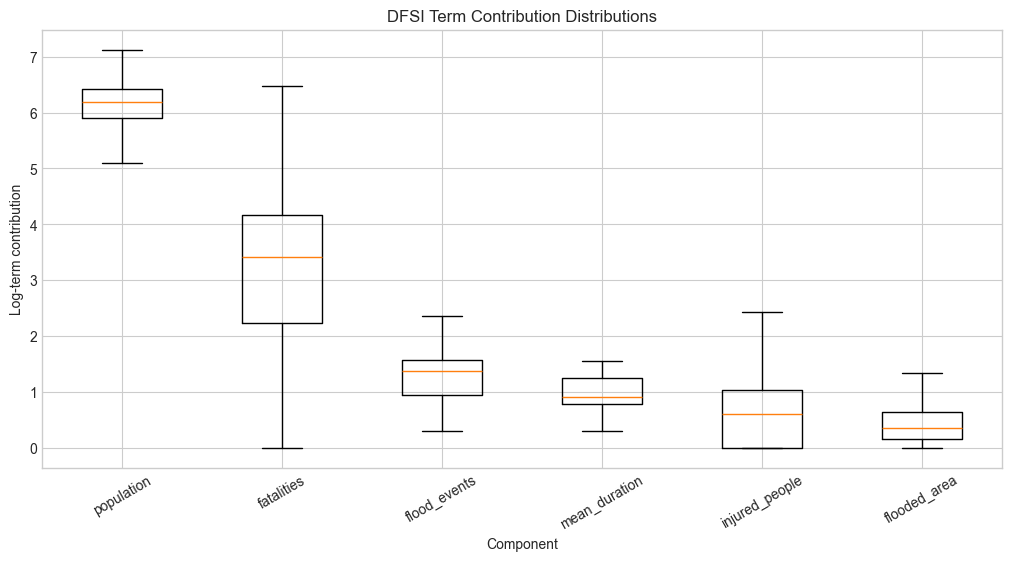

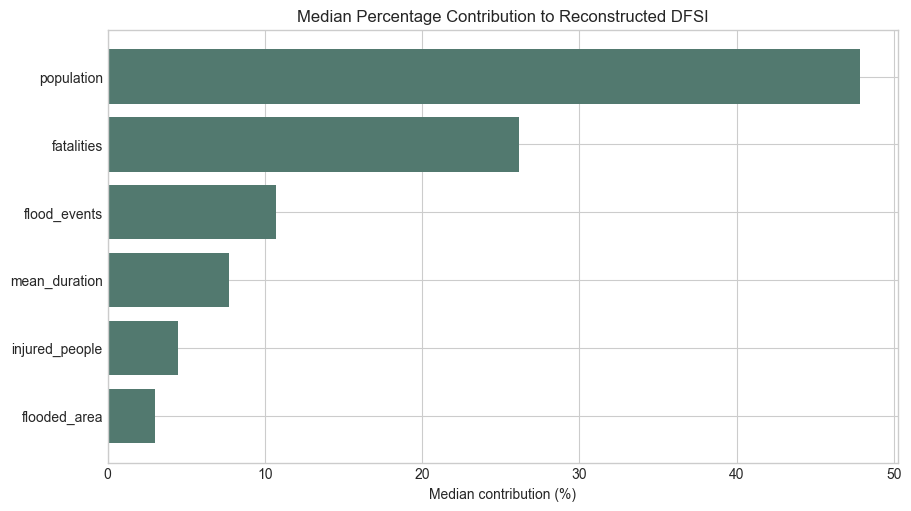

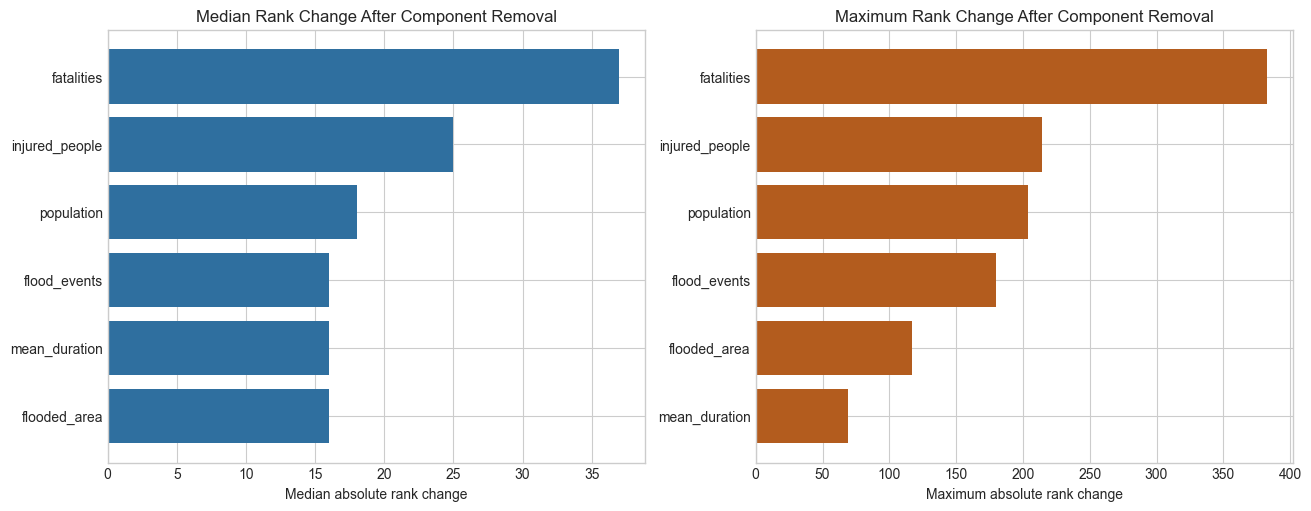

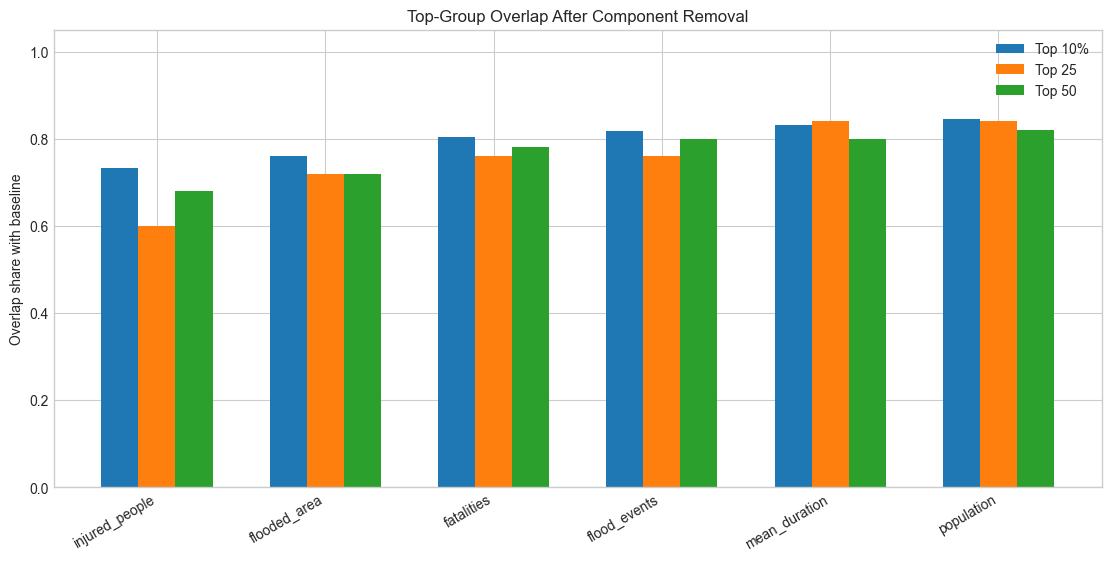

Saved figures:
- outputs/figures/dfsi_component_term_distributions.png (72,144 bytes)
- outputs/figures/dfsi_component_median_contributions.png (51,221 bytes)
- outputs/figures/dfsi_leave_one_out_rank_stability.png (75,393 bytes)
- outputs/figures/dfsi_leave_one_out_top_group_overlap.png (82,202 bytes)


In [6]:
plt.style.use("seaborn-v0_8-whitegrid")

component_order = component_summary.sort_values("median", ascending=False)["component"].tolist()
term_column_by_component = dict(zip(component_summary["component"], component_summary["term_column"]))
box_data = [analysis[term_column_by_component[component]] for component in component_order]

fig, ax = plt.subplots(figsize=(10, 5.5), constrained_layout=True)
ax.boxplot(box_data, labels=component_order, showfliers=False)
ax.set_title("DFSI Term Contribution Distributions")
ax.set_xlabel("Component")
ax.set_ylabel("Log-term contribution")
ax.tick_params(axis="x", rotation=30)
term_distribution_path = FIGURE_DIR / "dfsi_component_term_distributions.png"
fig.savefig(term_distribution_path, dpi=200, bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
median_contrib = component_summary.sort_values("median_percentage_contribution_to_total_dfsi", ascending=True)
ax.barh(median_contrib["component"], median_contrib["median_percentage_contribution_to_total_dfsi"], color="#52796f")
ax.set_title("Median Percentage Contribution to Reconstructed DFSI")
ax.set_xlabel("Median contribution (%)")
median_contrib_path = FIGURE_DIR / "dfsi_component_median_contributions.png"
fig.savefig(median_contrib_path, dpi=200, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
stability_order = loo_summary.sort_values("median_absolute_rank_change", ascending=False)
axes[0].barh(stability_order["removed_component"], stability_order["median_absolute_rank_change"], color="#2f6f9f")
axes[0].invert_yaxis()
axes[0].set_title("Median Rank Change After Component Removal")
axes[0].set_xlabel("Median absolute rank change")

max_order = loo_summary.sort_values("maximum_absolute_rank_change", ascending=False)
axes[1].barh(max_order["removed_component"], max_order["maximum_absolute_rank_change"], color="#b35c1e")
axes[1].invert_yaxis()
axes[1].set_title("Maximum Rank Change After Component Removal")
axes[1].set_xlabel("Maximum absolute rank change")
rank_stability_path = FIGURE_DIR / "dfsi_leave_one_out_rank_stability.png"
fig.savefig(rank_stability_path, dpi=200, bbox_inches="tight")
plt.show()

overlap_plot = loo_summary.sort_values("top_10_percent_overlap_share", ascending=True)
x = np.arange(len(overlap_plot))
width = 0.22
fig, ax = plt.subplots(figsize=(11, 5.5), constrained_layout=True)
ax.bar(x - width, overlap_plot["top_10_percent_overlap_share"], width, label="Top 10%")
ax.bar(x, overlap_plot["top_25_overlap_share"], width, label="Top 25")
ax.bar(x + width, overlap_plot["top_50_overlap_share"], width, label="Top 50")
ax.set_xticks(x)
ax.set_xticklabels(overlap_plot["removed_component"], rotation=30, ha="right")
ax.set_ylim(0, 1.05)
ax.set_title("Top-Group Overlap After Component Removal")
ax.set_ylabel("Overlap share with baseline")
ax.legend()
top_overlap_path = FIGURE_DIR / "dfsi_leave_one_out_top_group_overlap.png"
fig.savefig(top_overlap_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved figures:")
for path in [term_distribution_path, median_contrib_path, rank_stability_path, top_overlap_path]:
    print(f"- {path.relative_to(PROJECT_ROOT)} ({path.stat().st_size:,} bytes)")

## Concise Interpretation

In [7]:
most_numerical = component_summary.sort_values("median_percentage_contribution_to_total_dfsi", ascending=False).head(3)
most_rank_disruptive = loo_summary.sort_values("median_absolute_rank_change", ascending=False).iloc[0]
most_top10_disruptive = loo_summary.assign(top10_changed=lambda df: df["districts_entering_top_10_percent_count"] + df["districts_leaving_top_10_percent_count"]).sort_values("top10_changed", ascending=False).iloc[0]
high_corr_large_changes = loo_summary.query("spearman_correlation_with_complete_baseline_index > 0.95 and districts_moving_more_than_50_positions > 0")
wide_range_components = loo_summary.sort_values(["median_absolute_rank_change", "districts_moving_more_than_50_positions", "districts_entering_top_10_percent_count"], ascending=False).head(3)["removed_component"].tolist()

print("Concise interpretation")
print("A. Components contributing most to the numerical DFSI score:")
print(", ".join(f"{row.component} (median {row.median_percentage_contribution_to_total_dfsi:.1f}%)" for row in most_numerical.itertuples(index=False)))
print("B. Component removal changing district rankings most:")
print(f"{most_rank_disruptive.removed_component}, with median absolute rank change {most_rank_disruptive.median_absolute_rank_change:.1f} and maximum {most_rank_disruptive.maximum_absolute_rank_change:.0f}.")
print("C. Component most changing top-10% membership:")
print(f"{most_top10_disruptive.removed_component}, with {int(most_top10_disruptive.districts_entering_top_10_percent_count)} entering and {int(most_top10_disruptive.districts_leaving_top_10_percent_count)} leaving.")
print("D. Are high national rank correlations concealing large district-level changes?")
print(f"Yes. {len(high_corr_large_changes)} leave-one-out variants have Spearman > 0.95 while still moving some districts by more than 50 positions.")
print("E. Components for widest Monte Carlo weight ranges:")
print(", ".join(wide_range_components))

interpretation_summary = pd.DataFrame([
    {"question": "A", "answer": ", ".join(f"{row.component} (median {row.median_percentage_contribution_to_total_dfsi:.1f}%)" for row in most_numerical.itertuples(index=False))},
    {"question": "B", "answer": f"{most_rank_disruptive.removed_component}; median absolute rank change {most_rank_disruptive.median_absolute_rank_change:.1f}, maximum {most_rank_disruptive.maximum_absolute_rank_change:.0f}"},
    {"question": "C", "answer": f"{most_top10_disruptive.removed_component}; {int(most_top10_disruptive.districts_entering_top_10_percent_count)} entering and {int(most_top10_disruptive.districts_leaving_top_10_percent_count)} leaving top 10%"},
    {"question": "D", "answer": f"Yes; {len(high_corr_large_changes)} high-correlation variants still have >50-position district movements"},
    {"question": "E", "answer": ", ".join(wide_range_components)},
])
display(interpretation_summary)

Concise interpretation
A. Components contributing most to the numerical DFSI score:
population (median 47.8%), fatalities (median 26.1%), flood_events (median 10.7%)
B. Component removal changing district rankings most:
fatalities, with median absolute rank change 37.0 and maximum 383.
C. Component most changing top-10% membership:
injured_people, with 19 entering and 19 leaving.
D. Are high national rank correlations concealing large district-level changes?
Yes. 5 leave-one-out variants have Spearman > 0.95 while still moving some districts by more than 50 positions.
E. Components for widest Monte Carlo weight ranges:
fatalities, injured_people, population


,question,answer
0,A,"population (median 47.8%), fatalities (median 26.1%), flood_events (median 10.7%)"
1,B,"fatalities; median absolute rank change 37.0, maximum 383"
2,C,injured_people; 19 entering and 19 leaving top 10%
3,D,Yes; 5 high-correlation variants still have >50-position district movements
4,E,"fatalities, injured_people, population"


## Output Manifest

In [8]:
print("Saved outputs:")
for path in [
    TABLE_DIR / "dfsi_component_contribution_summary.csv",
    TABLE_DIR / "dfsi_component_contributions_by_district.csv",
    TABLE_DIR / "dfsi_leave_one_out_summary.csv",
    TABLE_DIR / "dfsi_leave_one_out_rankings.csv",
    TABLE_DIR / "dfsi_leave_one_out_top10_changes.csv",
    TABLE_DIR / "dfsi_leave_one_out_largest_changes.csv",
    FIGURE_DIR / "dfsi_component_term_distributions.png",
    FIGURE_DIR / "dfsi_component_median_contributions.png",
    FIGURE_DIR / "dfsi_leave_one_out_rank_stability.png",
    FIGURE_DIR / "dfsi_leave_one_out_top_group_overlap.png",
]:
    print(f"- {path.relative_to(PROJECT_ROOT)} ({path.stat().st_size:,} bytes)")

print("Monte Carlo simulations were not run in this notebook.")

Saved outputs:
- outputs/tables/dfsi_component_contribution_summary.csv (2,107 bytes)
- outputs/tables/dfsi_component_contributions_by_district.csv (249,715 bytes)
- outputs/tables/dfsi_leave_one_out_summary.csv (1,531 bytes)
- outputs/tables/dfsi_leave_one_out_rankings.csv (919,549 bytes)
- outputs/tables/dfsi_leave_one_out_top10_changes.csv (16,142 bytes)
- outputs/tables/dfsi_leave_one_out_largest_changes.csv (30,144 bytes)
- outputs/figures/dfsi_component_term_distributions.png (72,144 bytes)
- outputs/figures/dfsi_component_median_contributions.png (51,221 bytes)
- outputs/figures/dfsi_leave_one_out_rank_stability.png (75,393 bytes)
- outputs/figures/dfsi_leave_one_out_top_group_overlap.png (82,202 bytes)
Monte Carlo simulations were not run in this notebook.
